In [2]:
import sqlite3
import pandas as pd
import os
import numpy as np

# Paths relative to the repo root. PROJECT_ROOT is the repo's parent directory,
# which holds the data/results folders alongside this repo.
# PROJECT_ROOT = r'\\znas\Lab\Share\UNITMATCHTABLES_ENNY_CELIAN_JULIE\DeepUM_NatMeth2026V2'
PROJECT_ROOT = r'\\znas\Lab\Share\UNITMATCHTABLES_ENNY_CELIAN_JULIE\DeepUM_NatMeth2026_V3_OnMergedData'


def pandas_to_sqlite_type(dtype):
    """Maps pandas dtype to a suitable SQLite data type string."""
    if pd.api.types.is_integer_dtype(dtype):
        return "INTEGER"
    elif pd.api.types.is_float_dtype(dtype):
        return "REAL"
    elif pd.api.types.is_bool_dtype(dtype):
        return "INTEGER"  # Store bools as 0 or 1
    elif pd.api.types.is_datetime64_any_dtype(dtype):
        return "TEXT"  # Store datetimes as ISO format strings
    # Add other specific types if needed (e.g., timedelta)
    else:
        # Default to TEXT for object, string, category, etc.
        return "TEXT"


def merge_match_tables(df_1, df_2, sub1, sub2):
    """Merge two match-table dataframes by columns.

    The predefined shared columns are checked first: if they are present in both
    frames and equal within 1e-13, one copy is kept; if they differ more than
    that, an error is raised. All other columns are treated as unique to each
    input and are suffixed.
    """

    shared_columns_to_keep = ["RecSes 1", "RecSes 2", "ID1", "ID2", 
                              "ISI_correlations", "ISI_KL_divergence", "ISI_wasserstein_distance",
                              "FR_diff", "ISI_CV_diff",
                              "natim_correlations",
                              "UID orig 1", "UID orig 2"]
    tol = 1e-12

    suff_sub1 = f"_{sub1}" if sub1 is not None else ""
    suff_sub2 = f"_{sub2}" if sub2 is not None else ""

    df_1 = df_1.copy()
    df_2 = df_2.copy()

    for col in shared_columns_to_keep:
        if col in df_1.columns and col in df_2.columns:
            if not np.allclose(
                df_1[col].to_numpy(),
                df_2[col].to_numpy(),
                equal_nan=True,
                rtol=0.0,
                atol=tol,
            ):
                raise ValueError(f"Shared column '{col}' differs between inputs.")
            df_2.drop(columns=[col], inplace=True)
        elif col in df_1.columns or col in df_2.columns:
            raise KeyError(f"Expected shared column '{col}' is missing from one input frame.")

    for col in list(df_1.columns):
        if col not in shared_columns_to_keep:
            df_1.rename(columns={col: f"{col}{suff_sub1}"}, inplace=True)

    for col in list(df_2.columns):
        if col not in shared_columns_to_keep:
            df_2.rename(columns={col: f"{col}{suff_sub2}"}, inplace=True)

    return pd.concat([df_1, df_2], axis=1)


def import_csv_to_sqlite(mt_paths, models, m, p, l):

    db_file = os.path.join(PROJECT_ROOT, "matchtables.db")

    # Define the table name in SQLite
    table_name = f"{m}_{p}_{l}"  # Change this

    print(f"Reading data from the provided paths...")
    df_merged = pd.read_csv(mt_paths[0])
    if len(mt_paths) > 1:
        df_2 = pd.read_csv(mt_paths[1])
        df_merged = merge_match_tables(df_merged, df_2, models[0], models[1])
        for idx, path in enumerate(mt_paths[2:]):
            if os.path.exists(path):
                df_tomerge = pd.read_csv(path)
                df_merged = merge_match_tables(df_merged, df_tomerge, '', models[idx + 2])
            else:
                print(f"Warning: File not found at {path}. Skipping this file.")
    df_merged.rename(columns={'RecSes 1': 'RecSes1', 'RecSes 2': 'RecSes2'}, inplace=True)

    column_defs = []
    for col_name in df_merged.columns:
        print(col_name)

    print("Generating SQL column definitions from merged DataFrame...")
    for col_name in df_merged.columns:
        dtype = df_merged[col_name].dtype
        sql_type = pandas_to_sqlite_type(dtype)
        # Quote column names to handle spaces or reserved keywords
        safe_col_name = f'"{col_name}"'
        column_defs.append(f"{safe_col_name} {sql_type}")
        print(f"  - Column: '{col_name}', Pandas dtype: {dtype}, SQL type: {sql_type}")

    conn = None
    try:
        # Connect to the SQLite database (creates the file if it doesn't exist)
        conn = sqlite3.connect(db_file)
        cursor = conn.cursor()
        print(f"Successfully connected to database '{db_file}'")

        create_table_sql = (
            f"CREATE TABLE IF NOT EXISTS {table_name} ({', '.join(column_defs)});"
        )

        cursor.execute(create_table_sql)
        print(f"Table '{table_name}' checked/created successfully.")

        print(f"Importing data into table '{table_name}'...")
        # Use pandas.DataFrame.to_sql for easy import
        # if_exists='replace': Drops the table first and recreates it. Useful for initial load.
        # if_exists='append': Adds data to the existing table. Use if running multiple times.
        # if_exists='fail': Raises an error if the table already exists.
        df_merged.to_sql(table_name, conn, if_exists="replace", index=False)
        # index=False prevents pandas index from being written as a column

        print("Data imported successfully.")

        # Commit the changes (important!)
        conn.commit()
        print("Changes committed.")

    except sqlite3.Error as e:
        print(f"SQLite error: {e}")
        if conn:
            conn.rollback()  # Roll back changes if anything went wrong
    except pd.errors.EmptyDataError:
        print(
            f"Error: CSV file '{mt_paths[0]}' or '{mt_paths[1]}' or another one is empty or not found."
        )
    except Exception as e:
        print(f"An unexpected error occurred: {e}")
        if conn:
            conn.rollback()
    finally:
        # Close the connection
        if conn:
            conn.close()
            print("Database connection closed.")


In [13]:
data_root = PROJECT_ROOT
# models = ["DeepUnitMatch", "UMPy"]
models = ["DeepUnitMatch",
            "DUM_maxdist=20", "DUM_maxdist=50", "DUM_maxdist=100", "DUM_maxdist=inf", 
            "DUM_W_ij=1","DUM_W_ij=5","DUM_W_ij=10","DUM_W_ij=15","DUM_W_ij=20", 
            "n_output=8_after_ae_and_finetune", "n_output=32_after_ae_and_finetune", "n_output=128_after_ae_and_finetune", "n_output=256_after_ae_and_finetune", 
            "UMPy", 
            "UMPy_maxdist=20", "UMPy_maxdist=50", "UMPy_maxdist=100", "UMPy_maxdist=inf"
            ]

# for mouse in os.listdir(data_root):
#     if os.path.isdir(os.path.join(data_root, mouse)):
#         print(f"Processing mouse: {mouse}")
#         for probe in os.listdir(os.path.join(data_root, mouse)):
#             print(f"  Processing probe: {probe}")
#             for loc in os.listdir(os.path.join(data_root, mouse, probe)):
#                 print(f"    Processing location: {loc}")
#                 mt_paths = []
#                 models_found = []
#                 for model in models:
#                     mt_path = os.path.join(
#                         data_root, mouse, probe, loc, model, "MatchTable.csv"
#                     )
#                     if not os.path.exists(mt_path):
#                         print(f"      Warning: MatchTable.csv not found for {model} at {mt_path}")
#                     else:
#                         mt_paths.append(mt_path)
#                         models_found.append(model)

#                 # if len(mt_paths) > 0:
#                 #     import_csv_to_sqlite(mt_paths, models_found, mouse, probe, loc)
#                 # else:
#                 #     print('No valid MatchTable.csv found.')

In [2]:
db_file = os.path.join(PROJECT_ROOT, "matchtables.db")
# # mouse = "AL032"
# # probe = "19011111882"
# # loc = "2"
# mouse = "AL031"
# probe = "19011116684"
# loc = "1"
# mt_paths = []
# models_found = []
# for model in models:
#     mt_path = os.path.join(
#         data_root, mouse, probe, loc, model, "MatchTable.csv"
#     )
#     if not os.path.exists(mt_path):
#         print(f"      Warning: MatchTable.csv not found for {model} at {mt_path}")
#     else:
#         mt_paths.append(mt_path)
#         models_found.append(model)

# m = mouse
# p = probe
# l = loc
# # Define the table name in SQLite
# table_name = f"{m}_{p}_{l}"  # Change this

# print(f"Reading data from the provided paths...")
# df_merged = pd.read_csv(mt_paths[0])
# if len(mt_paths) > 1:
#     print(f"Reading")
#     df_2 = pd.read_csv(mt_paths[1])
#     print(f"Merging")
#     df_merged = merge_match_tables(df_merged, df_2, models[0], models[1])
#     for idx, path in enumerate(mt_paths[2:]):
#         if os.path.exists(path):
#             print(f"Reading")
#             df_tomerge = pd.read_csv(path)
#             print(f"Merging")
#             df_merged = merge_match_tables(df_merged, df_tomerge, None, models[idx + 2])

#             if "Matches_" in df_merged.keys():
#                 print(path)
#         else:
#             print(f"Warning: File not found at {path}. Skipping this file.")
# df_merged.rename(columns={'RecSes 1': 'RecSes1', 'RecSes 2': 'RecSes2'}, inplace=True)

In [27]:
# df_1 = pd.read_csv(mt_paths[0])
# df_2 = pd.read_csv(mt_paths[1])
df_merged = merge_match_tables(df_1, df_2, models[0], models[1])

RecSes 1
RecSes 2
ID1
ID2
ISI_correlations
ISI_KL_divergence
ISI_wasserstein_distance
FR_diff
ISI_CV_diff
natim_correlations


KeyError: "Expected shared column 'natim_correlations' is missing from one input frame."

In [30]:
for key in df_merged.keys():
    print(key)

ID1
ID2
RecSes1
RecSes2
Matches_DeepUnitMatch
UM Probabilities_DeepUnitMatch
TotalScore_DeepUnitMatch
distance_DeepUnitMatch
ISI_correlations
ISI_KL_divergence
ISI_wasserstein_distance
refpop_correlations_DeepUnitMatch
FR_diff
ISI_CV_diff
UID orig 1
UID orig 2
UID Lib 1_DeepUnitMatch
UID Lib 2_DeepUnitMatch
UID 1_DeepUnitMatch
UID 2_DeepUnitMatch
UID Cons 1_DeepUnitMatch
UID Cons 2_DeepUnitMatch
Matches_DUM_maxdist=20
UM Probabilities_DUM_maxdist=20
TotalScore_DUM_maxdist=20
distance_DUM_maxdist=20
refpop_correlations_DUM_maxdist=20
UID Lib 1_DUM_maxdist=20
UID Lib 2_DUM_maxdist=20
UID 1_DUM_maxdist=20
UID 2_DUM_maxdist=20
UID Cons 1_DUM_maxdist=20
UID Cons 2_DUM_maxdist=20
Matches_DUM_maxdist=50
UM Probabilities_DUM_maxdist=50
TotalScore_DUM_maxdist=50
distance_DUM_maxdist=50
refpop_correlations_DUM_maxdist=50
UID Lib 1_DUM_maxdist=50
UID Lib 2_DUM_maxdist=50
UID 1_DUM_maxdist=50
UID 2_DUM_maxdist=50
UID Cons 1_DUM_maxdist=50
UID Cons 2_DUM_maxdist=50
Matches_DUM_maxdist=100
UM Probab

In [13]:
column_defs = []
for col_name in df_merged.columns:
    print(col_name)

print("Generating SQL column definitions from merged DataFrame...")
for col_name in df_merged.columns:
    dtype = df_merged[col_name].dtype
    sql_type = pandas_to_sqlite_type(dtype)
    # Quote column names to handle spaces or reserved keywords
    safe_col_name = f'"{col_name}"'
    column_defs.append(f"{safe_col_name} {sql_type}")
    print(f"  - Column: '{col_name}', Pandas dtype: {dtype}, SQL type: {sql_type}")

ID1
ID2
RecSes1
RecSes2
Matches_DeepUnitMatch
UM Probabilities_DeepUnitMatch
TotalScore_DeepUnitMatch
distance_DeepUnitMatch
ISI_correlations
ISI_KL_divergence
ISI_wasserstein_distance
refpop_correlations_DeepUnitMatch
FR_diff
ISI_CV_diff
UID orig 1
UID orig 2
UID Lib 1_DeepUnitMatch
UID Lib 2_DeepUnitMatch
UID 1_DeepUnitMatch
UID 2_DeepUnitMatch
UID Cons 1_DeepUnitMatch
UID Cons 2_DeepUnitMatch
natim_correlations_DeepUnitMatch
Matches_DUM_maxdist=20
UM Probabilities_DUM_maxdist=20
TotalScore_DUM_maxdist=20
distance_DUM_maxdist=20
refpop_correlations_DUM_maxdist=20
UID Lib 1_DUM_maxdist=20
UID Lib 2_DUM_maxdist=20
UID 1_DUM_maxdist=20
UID 2_DUM_maxdist=20
UID Cons 1_DUM_maxdist=20
UID Cons 2_DUM_maxdist=20
Generating SQL column definitions from merged DataFrame...
  - Column: 'ID1', Pandas dtype: float64, SQL type: REAL
  - Column: 'ID2', Pandas dtype: float64, SQL type: REAL
  - Column: 'RecSes1', Pandas dtype: float64, SQL type: REAL
  - Column: 'RecSes2', Pandas dtype: float64, SQL 

In [14]:
conn = None

# Connect to the SQLite database (creates the file if it doesn't exist)
conn = sqlite3.connect(db_file)
cursor = conn.cursor()
print(f"Successfully connected to database '{db_file}'")

create_table_sql = (
    f"CREATE TABLE IF NOT EXISTS {table_name} ({', '.join(column_defs)});"
)

cursor.execute(create_table_sql)
print(f"Table '{table_name}' checked/created successfully.")

print(f"Importing data into table '{table_name}'...")
# Use pandas.DataFrame.to_sql for easy import
# if_exists='replace': Drops the table first and recreates it. Useful for initial load.
# if_exists='append': Adds data to the existing table. Use if running multiple times.
# if_exists='fail': Raises an error if the table already exists.
df_merged.to_sql(table_name, conn, if_exists="replace", index=False)
# index=False prevents pandas index from being written as a column

print("Data imported successfully.")

Successfully connected to database '\\znas\Lab\Share\UNITMATCHTABLES_ENNY_CELIAN_JULIE\DeepUM_NatMeth2026_V3_OnMergedData\matchtables.db'
Table 'AL032_19011111882_2' checked/created successfully.
Importing data into table 'AL032_19011111882_2'...
Data imported successfully.


In [ ]:
# df_1 = pd.read_csv(mt_paths[0])

0                NaN
1                NaN
2                NaN
3                NaN
4                NaN
              ...   
24780479    0.010128
24780480   -0.004344
24780481    0.004899
24780482    0.042023
24780483    0.040894
Name: natim_correlations_DeepUnitMatch, Length: 24780484, dtype: float64

In [29]:
tmp1 = df_merged[df_merged['ISI_correlations_DeepUnitMatch'] != df_merged['ISI_correlations_DUM_maxdist=20']]['ISI_correlations_DeepUnitMatch'].values
tmp2 = df_merged[df_merged['ISI_correlations_DeepUnitMatch'] != df_merged['ISI_correlations_DUM_maxdist=20']]['ISI_correlations_DUM_maxdist=20'].values

tmp2[0] == tmp1[0]

False

In [ ]:
import sqlite3
from pathlib import Path

db_path = Path(r"\\znas\Lab\Share\UNITMATCHTABLES_ENNY_CELIAN_JULIE\DeepUM_NatMeth2026_V3_OnMergedData\matchtables_algo.db")
col = "natim_correlations_DeepUnitMatch"
# col = 'refpop_correlations_UMPy'

conn = sqlite3.connect(db_path)
cur = conn.cursor()

tables = [
    r[0] for r in cur.execute("""
        SELECT name
        FROM sqlite_master
        WHERE type = 'table' AND name NOT LIKE 'sqlite_%'
        ORDER BY name
    """)
]

print("Tables:", len(tables))
# for table in tables:
table = "AL032_19011111882_2"
# table = "JF084_Probe1_IMRO_8"
# table = "AV008_Probe1_IMRO_6"
cols = [r[1] for r in cur.execute(f"PRAGMA table_info({repr(table)})")]
print(f"\n{table}")
print("  columns:", cols[:10], "..." if len(cols) > 10 else "")
if col in cols:
    n_rows = cur.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0]
    n_nonempty = cur.execute(f"SELECT COUNT(*) FROM {table} WHERE {col} IS NOT NULL AND TRIM(CAST({col} AS TEXT)) != ''").fetchone()[0]
    print(f"  {col}: rows={n_rows}, non-empty={n_nonempty}")
else:
    print(f"  {col}: not present")

conn.close()

Tables: 171

AL032_19011111882_2
  columns: ['ID1', 'ID2', 'RecSes1', 'RecSes2', 'Matches_DeepUnitMatch', 'UM Probabilities_DeepUnitMatch', 'TotalScore_DeepUnitMatch', 'distance_DeepUnitMatch', 'ISI_correlations', 'ISI_KL_divergence'] ...


In [1]:
models = [
            # "DeepUnitMatch",
            # "UMPy", 
            # "EMD", 
            # "DANT", 
            # "DANT_no_functional",
            "DUM_untrained", "DUM_unfinetuned", "DUM_finetuned_only",
            # "DUM_maxdist=20", "DUM_maxdist=50", "DUM_maxdist=100", "DUM_maxdist=inf", 
            # "UMPy_maxdist=20", "UMPy_maxdist=50", "UMPy_maxdist=100", "UMPy_maxdist=inf",
            # "DUM_W_ij=1","DUM_W_ij=5","DUM_W_ij=10","DUM_W_ij=15","DUM_W_ij=20", 
            # "n_output=8_after_ae_and_finetune", "n_output=32_after_ae_and_finetune", "n_output=128_after_ae_and_finetune", "n_output=256_after_ae_and_finetune", 
            ]

col_names = [f"UM Probabilities_{model}" for model in models]

# Build SQL query based on available columns
base_cols = ["ID1", "ID2", "RecSes1", "RecSes2", "ISI_correlations", "ISI_KL_divergence", "ISI_wasserstein_distance", 
                "FR_diff", "ISI_CV_diff", "natim_correlations_DeepUnitMatch"]
base_cols += [name.replace("UM Probabilities", "refpop_correlations") for name in col_names]

In [2]:
[name.replace("UM Probabilities", "refpop_correlations") for name in col_names]

['refpop_correlations_DUM_untrained',
 'refpop_correlations_DUM_unfinetuned',
 'refpop_correlations_DUM_finetuned_only']

In [3]:
mouse = "AL032"
probe = "19011111882"
loc = "1"
# mouse = "AV008"
# probe = "Probe0"
# loc = "IMRO_12"
# mouse = "AL036"
# probe = "19011116882"
# loc = "2"

import pandas as pd
def quote_ident(name):
    return '"' + str(name).replace('"', '""') + '"'

import sqlite3
from pathlib import Path

db_path = Path(r"\\znas\Lab\Share\UNITMATCHTABLES_ENNY_CELIAN_JULIE\DeepUM_NatMeth2026_V3_OnMergedData\matchtables_training.db")

conn = sqlite3.connect(db_path)
cursor = conn.cursor()
cursor.execute(f"PRAGMA table_info('{mouse}_{probe}_{loc}')")
columns = [column[1] for column in cursor.fetchall()]
if not columns:
    print(f"Table {mouse}_{probe}_{loc} has no columns.")
    conn.close()

all_cols = base_cols + col_names

query_cols = ", ".join(quote_ident(col) for col in all_cols)
table_name = quote_ident(f"{mouse}_{probe}_{loc}")
query = f"SELECT {query_cols} FROM {table_name};"

# Single database query for all needed data
mt = pd.read_sql_query(query, conn)

conn.close()

mt

Table AL032_19011111882_1 has no columns.


ProgrammingError: Cannot operate on a closed database.

In [26]:
mt.keys()

Index(['FR_diff', 'ID1', 'ID2', 'ISI_CV_diff', 'ISI_KL_divergence',
       'ISI_correlations', 'ISI_wasserstein_distance', 'RecSes1', 'RecSes2',
       '"natim_correlations_DeepUnitMatch"', 'refpop_correlations_DANT',
       'refpop_correlations_DANT_no_functional',
       'refpop_correlations_DeepUnitMatch', 'refpop_correlations_EMD',
       'refpop_correlations_UMPy', 'UM Probabilities_DeepUnitMatch',
       'UM Probabilities_UMPy', 'UM Probabilities_EMD',
       'UM Probabilities_DANT', 'UM Probabilities_DANT_no_functional'],
      dtype='object')

In [31]:
# rename without the "..."
mt = mt.rename(columns={col: col.replace('"', '') for col in mt.keys() if '"' in col})

for col in all_cols:
    mt[col] = pd.to_numeric(mt[col], errors='coerce')

mt.keys()


Index(['ID1', 'ID2', 'RecSes1', 'RecSes2', 'ISI_correlations',
       'ISI_KL_divergence', 'ISI_wasserstein_distance', 'FR_diff',
       'ISI_CV_diff', 'natim_correlations_DeepUnitMatch',
       'refpop_correlations_DeepUnitMatch', 'refpop_correlations_UMPy',
       'refpop_correlations_EMD', 'refpop_correlations_DANT',
       'refpop_correlations_DANT_no_functional',
       'UM Probabilities_DeepUnitMatch', 'UM Probabilities_UMPy',
       'UM Probabilities_EMD', 'UM Probabilities_DANT',
       'UM Probabilities_DANT_no_functional'],
      dtype='object')

In [76]:
def AUC(mt, indices, func_metric):
    """
    Optimized version of AUC calculation function.
    """
    matches_indices = set(indices)
    P = len(matches_indices)
    if P < 1:
        return np.nan

    # Filter only across-session matches
    across = mt.loc[mt["RecSes1"] != mt["RecSes2"]]

    # Get the total number of non-matches
    N_a = len(across) - P

    if N_a <= 0:  # Edge case protection
        return np.nan

    sorted_indices = across.sort_values(by=func_metric, ascending=False).index

    is_match = np.array([idx in matches_indices for idx in sorted_indices], dtype=bool)

    # Calculate cumulative values
    tp_cumsum = np.cumsum(is_match)
    fp_cumsum = np.cumsum(~is_match)

    # Calculate recall and false positive rate arrays
    recall = tp_cumsum / P
    fpr = fp_cumsum / N_a

    auc = np.trapezoid(recall, fpr)

    return auc

import numpy as np
from testing.test import remove_conflicts2, directional_filter
import random 
def get_matches_1model(mt, metric, fixed_n: int = None):
    """
    Get the matches for one model, given a merged match table (for one session pair).
    If a fixed number of matches is set, we don't do similarity thresholding.
    Always do conflict resolution.

    Spatial filtering is not applied here: the model column already encodes spatial
    information (e.g. the _40Spat / _80Spat / _NoSpat variants).
    """
    # Filter data once before processing to avoid repeated filtering
    across = mt.loc[
        (mt["RecSes1"] != mt["RecSes2"]), [metric, "RecSes1", "RecSes2", "ID1", "ID2"]
    ]

    if not fixed_n:
        if "UM Probabilities" in metric :
            thresh = 0.5
        else:
            thresh = get_threshold_df(mt, metric=metric)

            within = mt.loc[
                (mt["RecSes1"] == mt["RecSes2"]),
                [metric, "ID1", "ID2", "RecSes1", "RecSes2"],
            ]
            # Correct for different median similarities between within- and across-day sets.
            diff = np.median(within[metric]) - np.median(across[metric])
            thresh = thresh - diff

        # Apply thresholds to generate matches
        matches = across.loc[
            across[metric] >= thresh, ["RecSes1", "RecSes2", "ID1", "ID2", metric]
        ]
    else:
        # For fixed_n, sort once and reuse
        if metric == "centroid_distance":
            matches = across.sort_values(by=metric, ascending=True)
        else:
            matches = across.sort_values(by=metric, ascending=False)


    # Only allow a match if it is above threshold when comparing in both directions
    matches = directional_filter(matches)

    # Then average
    matches = avg_across_directions(matches, columns=[metric])

    if len(matches) != 0:
        # Resolve conflict matches by only keeping the match with highest similarity
        matches, num_conflicts = remove_conflicts2(matches, metric)

    # Ensure consistent ordering (keep a single direction per session pair)
    matches = matches.loc[matches["RecSes1"] < matches["RecSes2"]]
 
    # Add a random timebreaker column to randomize order of ties 
    if not matches.empty:
        matches["random_tiebreaker"] = [random.random() for _ in range(len(matches))]  
        matches = matches.sort_values(by=[metric, "random_tiebreaker"], ascending=[False, True])
        matches = matches.drop(columns=["random_tiebreaker"])
    
    if fixed_n is not None:
        matches = matches.head(fixed_n) # keep best N matches
    else:
        matches = matches.loc[matches[metric] >= thresh]
 
    return matches.index.to_list(), matches

from sklearn.metrics import roc_auc_score

def AUC_sklearn(mt, indices, func_metric):
    across = mt.loc[mt["RecSes1"] != mt["RecSes2"]].copy()

    mask = across[func_metric].notna()
    across = across.loc[mask]

    if across.empty:
        return np.nan

    y_true = across.index.isin(indices).astype(int)
    y_score = across[func_metric].to_numpy()

    if len(np.unique(y_true)) < 2:
        return np.nan

    return roc_auc_score(y_true, y_score)

import sys, os
sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), "DeepUnitMatch"))
from utils.helpers import pick, avg_across_directions
# df = mt[(mt["RecSes1"] == 4) & (mt["RecSes2"] == 5)]
df = pick(mt, 1, 2, False)

func_metric = "refpop_correlations_DeepUnitMatch"

matches_indices, matches = get_matches_1model(df, "UM Probabilities_DeepUnitMatch") 

model_name = 'UM Probabilities_DeepUnitMatch'
metrics = ["ISI_correlations", "FR_diff", "ISI_CV_diff", 
            "refpop_correlations_DeepUnitMatch", model_name.replace("UM Probabilities", "refpop_correlations"), "natim_correlations_DeepUnitMatch"]
if "refpop_correlations_UMPy" in df.keys():
    metrics.append("refpop_correlations_UMPy")
metrics = list(dict.fromkeys(metrics))
print(np.shape(df))
print(df)
df = avg_across_directions(df, columns=metrics) 

auc1 = AUC_sklearn(df, matches_indices, func_metric)
auc2 = AUC_sklearn(df[df['RecSes1'] < df['RecSes2']], matches_indices, func_metric)
print(auc1)
print(auc2)
print(len(matches_indices))
matches

(1681, 20)
        ID1    ID2  RecSes1  RecSes2  ISI_correlations  ISI_KL_divergence  \
0       1.0    1.0      1.0      1.0          0.997690           0.008341   
1      17.0    1.0      1.0      1.0          0.934327           0.162832   
2      29.0    1.0      1.0      1.0          0.761836           0.275325   
3      30.0    1.0      1.0      1.0          0.624287           0.469313   
4      36.0    1.0      1.0      1.0         -0.029043           5.841306   
...     ...    ...      ...      ...               ...                ...   
1676  111.0  128.0      2.0      2.0          0.924486           0.134878   
1677  123.0  128.0      2.0      2.0         -0.127423           1.672919   
1678  124.0  128.0      2.0      2.0          0.503916           0.688159   
1679  125.0  128.0      2.0      2.0         -0.351925           1.848503   
1680  128.0  128.0      2.0      2.0          0.982121           0.300427   

      ISI_wasserstein_distance     FR_diff  ISI_CV_diff  \
0    

,RecSes1,RecSes2,ID1,ID2,UM Probabilities_DeepUnitMatch
1530,1.0,2.0,135.0,123.0,0.999962
904,1.0,2.0,29.0,26.0,0.999962
1330,1.0,2.0,179.0,91.0,0.999953
1655,1.0,2.0,147.0,128.0,0.999935
1158,1.0,2.0,75.0,79.0,0.999899
990,1.0,2.0,50.0,51.0,0.999893
1032,1.0,2.0,60.0,63.0,0.999833
1116,1.0,2.0,73.0,78.0,0.999802
1579,1.0,2.0,193.0,124.0,0.999788
947,1.0,2.0,36.0,36.0,0.998220


In [56]:
df

,ID1,ID2,RecSes1,RecSes2,ISI_correlations,ISI_KL_divergence,ISI_wasserstein_distance,FR_diff,ISI_CV_diff,natim_correlations_DeepUnitMatch,refpop_correlations_DeepUnitMatch,refpop_correlations_UMPy,refpop_correlations_EMD,refpop_correlations_DANT,refpop_correlations_DANT_no_functional,UM Probabilities_DeepUnitMatch,UM Probabilities_UMPy,UM Probabilities_EMD,UM Probabilities_DANT,UM Probabilities_DANT_no_functional
902,1.0,26.0,1.0,2.0,0.416970,2.979928,0.121971,18.041612,0.122414,NaN,0.161766,0.089173,0.294947,0.042714,0.042714,0.000423,8.220068e-08,0.0,0.0,0.0
903,17.0,26.0,1.0,2.0,0.574458,0.326424,0.078889,9.478597,7.639749,NaN,0.212129,0.154280,0.386622,0.355492,0.355492,0.000485,9.201389e-06,0.0,0.0,0.0
904,29.0,26.0,1.0,2.0,0.877577,0.540317,0.072400,3.849503,0.093222,NaN,0.866898,0.788119,0.857984,0.102772,0.102772,0.999956,9.990898e-01,1.0,1.0,1.0
905,30.0,26.0,1.0,2.0,0.825934,0.143380,0.024193,2.334151,7.108798,NaN,0.183154,0.157279,-0.624274,0.387206,0.387206,0.038833,1.389835e-05,0.0,0.0,0.0
906,36.0,26.0,1.0,2.0,-0.366603,11.474096,0.153700,173.143996,0.283157,NaN,0.444507,0.402372,-0.009952,0.385709,0.385709,0.044674,7.918912e-04,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1657,150.0,128.0,1.0,2.0,0.581964,1.004812,0.033109,19.199685,0.911961,NaN,0.223718,0.261026,0.381628,-0.162229,-0.162229,0.039978,8.052859e-06,0.0,0.0,0.0
1658,179.0,128.0,1.0,2.0,0.076380,1.312775,0.181583,31.655175,0.855412,NaN,-0.026738,0.072236,0.930255,-0.602905,-0.602905,0.000480,1.393771e-05,0.0,0.0,0.0
1659,180.0,128.0,1.0,2.0,0.043998,2.039026,0.311172,33.718612,0.986764,NaN,0.068732,0.158468,0.923753,-0.512053,-0.512053,0.000598,1.834552e-05,0.0,0.0,0.0
1660,189.0,128.0,1.0,2.0,0.714623,0.479820,0.101997,28.325154,1.269278,NaN,0.137517,0.270624,0.178916,0.106719,0.106719,0.001130,2.449607e-03,0.0,0.0,0.0


In [57]:
df = avg_across_directions(df, columns=metrics)   


KeyError: "None of [MultiIndex([(2.0,  26.0, 1.0,   1.0),\n            (2.0,  26.0, 1.0,  17.0),\n            (2.0,  26.0, 1.0,  29.0),\n            (2.0,  26.0, 1.0,  30.0),\n            (2.0,  26.0, 1.0,  36.0),\n            (2.0,  26.0, 1.0,  46.0),\n            (2.0,  26.0, 1.0,  50.0),\n            (2.0,  26.0, 1.0,  60.0),\n            (2.0,  26.0, 1.0,  70.0),\n            (2.0,  26.0, 1.0,  73.0),\n            ...\n            (2.0, 128.0, 1.0, 108.0),\n            (2.0, 128.0, 1.0, 135.0),\n            (2.0, 128.0, 1.0, 141.0),\n            (2.0, 128.0, 1.0, 147.0),\n            (2.0, 128.0, 1.0, 148.0),\n            (2.0, 128.0, 1.0, 150.0),\n            (2.0, 128.0, 1.0, 179.0),\n            (2.0, 128.0, 1.0, 180.0),\n            (2.0, 128.0, 1.0, 189.0),\n            (2.0, 128.0, 1.0, 193.0)],\n           names=['RecSes1', 'ID1', 'RecSes2', 'ID2'], length=418)] are in the [index]"

In [42]:
metrics

['ISI_correlations',
 'FR_diff',
 'ISI_CV_diff',
 'refpop_correlations_DeepUnitMatch',
 'refpop_correlations_EMD',
 'natim_correlations_DeepUnitMatch',
 'refpop_correlations_UMPy']

0.9564226925338035 162 0.6403162055335968
0.9874828532235939 162 0.6403162055335968
0.9762639623750734 162 0.6403162055335968


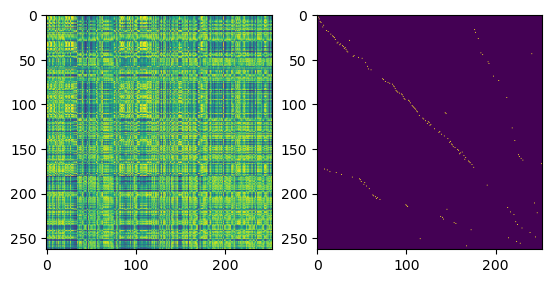

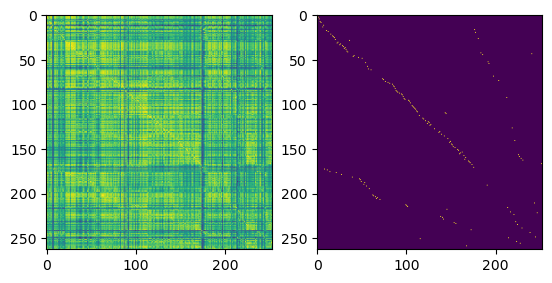

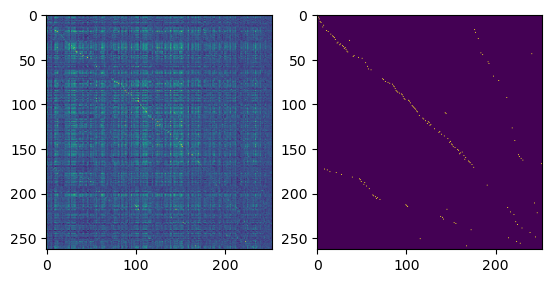

In [244]:
def pairwise_match_score_exact(S, M):
    """
    Calculate the average pairwise ranking score of all model-selected
    matches according to S.

    Parameters
    ----------
    S : ndarray, shape (N1, N2)
        Similarity matrix.

    M : ndarray, shape (N1, N2)
        Binary matching matrix. M[i, j] == 1 means that (i, j) is
        selected as a match by the model.

    Returns
    -------
    dict
        score: average pairwise score across all selected matches.
               Win = 1, tie = 0.5, loss = 0.

        n_matches: total number of selected matches.

        coverage: fraction of units in dataset 1 for which at least
                  one match was made.
    """

    S = np.asarray(S)
    M = np.asarray(M)

    if S.shape != M.shape:
        raise ValueError("S and M must have the same shape.")

    N1, N2 = S.shape

    scores = []

    for i in range(N1):

        # All matches selected by the model for unit i
        matches = np.flatnonzero(M[i])

        for j in matches:

            # S value of this particular model-selected match
            model_S = S[i, j]

            # All alternative candidates for this unit
            alternatives = np.delete(S[i], j)

            # Pairwise wins and ties
            wins = np.sum(model_S > alternatives)
            ties = np.sum(model_S == alternatives)

            # Tie receives half credit
            score = (wins + 0.5 * ties) / len(alternatives)

            scores.append(score)

    n_matches = len(scores)

    # Number of units with at least one match
    n_units_matched = np.sum(np.any(M != 0, axis=1))

    return {
        "score": np.mean(scores) if scores else np.nan,
        "n_matches": n_matches,
        "coverage": n_units_matched / np.min([N1, N2]),
    }

def build_S_and_M(df, match_indices, metric="ISI_correlations"):
    """
    Build S and M for a single session pair.

    Parameters
    ----------
    df : pd.DataFrame
        Subset for one r1/r2 pair, containing at least:
        ID1, ID2, and the metric column (e.g. "ISI_correlations").
    match_indices : list-like
        Row indices in df that are selected matches.
    metric : str
        Name of the pairwise similarity metric to store in S.

    Returns
    -------
    S : np.ndarray, shape (N1, N2)
        Similarity matrix.
    M : np.ndarray, shape (N1, N2)
        Binary match matrix.
    """
    # Keep only actual unit-to-unit pairs from this session pair
    d = df.copy()
    d = d.loc[d["RecSes1"] < d["RecSes2"]].copy()

    # Sort unique neuron IDs for deterministic matrix indexing
    ids1 = sorted(d["ID1"].unique())
    ids2 = sorted(d["ID2"].unique())

    i_map = {u: i for i, u in enumerate(ids1)}
    j_map = {u: j for j, u in enumerate(ids2)}

    N1, N2 = len(ids1), len(ids2)
    S = np.full((N1, N2), -np.inf, dtype=float)
    M = np.zeros((N1, N2), dtype=int)

    # Fill similarity values for all observed pairs
    for idx, row in d.iterrows():
        i = i_map.get(row["ID1"])
        j = j_map.get(row["ID2"])
        if i is not None and j is not None:
            S[i, j] = row[metric]

    # Fill selected matches
    for idx in match_indices:
        if idx not in d.index:
            continue
        row = d.loc[idx]
        i = i_map.get(row["ID1"])
        j = j_map.get(row["ID2"])
        if i is not None and j is not None:
            M[i, j] = 1

    return S, M

import os, sys
sys.path.insert(0, r"C:\Users\celia\OneDrive - University College London\Documents\GitHub\UnitMatch\UnitMatchPy\DeepUnitMatch")
from utils.helpers import pick

# model_name = 'UM Probabilities_DeepUnitMatch'
# model_name = 'UM Probabilities_UMPy'
model_name = 'UM Probabilities_DANT'

df = pick(mt, 4, 5)
match_indices, _ = get_matches_1model(df, metric=model_name, fixed_n=None)

# metrics = ["ISI_correlations"]
metrics = ["ISI_correlations", model_name.replace("UM Probabilities", "refpop_correlations"), "natim_correlations_DeepUnitMatch"]
for metric in metrics:

    # Test single-match metric
    S, M = build_S_and_M(df, match_indices, metric=metric)
    single_match_result = pairwise_match_score_exact(S, M)
    print(single_match_result["score"], single_match_result["n_matches"], single_match_result["coverage"])

    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1,2)
    ax[0].imshow(S)
    ax[1].imshow(M)

In [1]:
import os
import sys
sys.path.insert(0, os.path.dirname(os.getcwd()))
sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), "DeepUnitMatch"))
sys.path = list(set(sys.path))
from utils.helpers import get_locations_from_sqlite

# Get all valid locations first to avoid repeated file system checks
valid_locations1 = get_locations_from_sqlite(
    db_path=r"\\znas\Lab\Share\UNITMATCHTABLES_ENNY_CELIAN_JULIE\DeepUM_NatMeth2026_V3_OnMergedData\matchtables_xval.db" 
)

# Get all valid locations first to avoid repeated file system checks
valid_locations2 = get_locations_from_sqlite(
    db_path=r"\\znas\Lab\Share\UNITMATCHTABLES_ENNY_CELIAN_JULIE\DeepUM_NatMeth2026_V3_OnMergedData\matchtables_algo.db" 
)

In [2]:
for location in valid_locations2:
    if location not in valid_locations1:
        print(location)

In [4]:
from utils.helpers import (
    PROJECT_ROOT,
    create_um_lookup
)
import pandas as pd
import os

ref_model = 'DeepUnitMatch'
# ref_model = 'DANT_no_functional'
# ref_model = 'DANT'

results_dir = os.path.join(PROJECT_ROOT, "results")

# Load UM_results once and create a lookup dictionary for fast access
UM_results = pd.read_csv(os.path.join(results_dir, f"UM Probabilities_{ref_model}_results.csv"))
um_lookup = create_um_lookup(UM_results)

In [10]:
mouse = 'AL032'
probe = '19011111882'
loc = '2'
lookup_key = (mouse, probe, loc)
UM_N = um_lookup.get(lookup_key)
UM_N

,mouse,probe,loc,day1,day2,r1,r2,AUC_isi,AUC_isi_KL,AUC_isi_Wasserstein,AUC_fr,AUC_fr_norm,AUC_isi_cv,AUC_refpop_UMPy,AUC_refpop_DeepUnitMatch,AUC_refpop_model,AUC_natim,N,delta_days
0,AL032,19011111882,2,0,3,1.0,2.0,0.857174,0.118262,0.187731,0.327324,0.245979,0.251678,0.878725,0.822538,0.822538,NaN,33,3
1,AL032,19011111882,2,0,4,1.0,3.0,0.889582,0.098790,0.187989,0.321325,0.252303,0.217100,0.900115,0.912286,0.912286,NaN,55,4
2,AL032,19011111882,2,0,12,1.0,4.0,0.852225,0.121214,0.114739,0.307220,0.183242,0.416077,0.687814,0.727407,0.727407,NaN,14,12
3,AL032,19011111882,2,0,13,1.0,5.0,0.971374,0.032212,0.092501,0.308520,0.137735,0.317143,0.529259,0.850463,0.850463,NaN,13,13
4,AL032,19011111882,2,0,24,1.0,6.0,0.907500,0.086810,0.140791,0.154201,0.044764,0.329574,0.660013,0.710567,0.710567,NaN,10,24
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
414,AL032,19011111882,2,143,207,18.0,20.0,0.859806,0.160242,0.175537,0.408592,0.225980,0.235180,0.866169,0.925919,0.925919,0.705441,59,64
415,AL032,19011111882,2,143,235,18.0,21.0,0.878151,0.194224,0.057409,0.491908,0.134209,0.184308,0.892880,0.519989,0.519989,0.266573,4,92
416,AL032,19011111882,2,188,207,19.0,20.0,0.754809,0.215371,0.289284,0.362175,0.267632,0.417951,0.803411,0.827808,0.827808,NaN,85,19
417,AL032,19011111882,2,188,235,19.0,21.0,0.686858,0.234189,0.337374,0.345412,0.276504,0.282269,0.648902,0.772277,0.772277,NaN,8,47
